# 9. Tracking data II: real DSN data

> Process the real OSIRIS-REx tracking pass of June 8, 2018: read the converted TRK-2-34 file, set up the precise light-time measurement models with their auxiliary data and media corrections, validate them against the flight team's reconstructed trajectory, edit the outliers, and fit Doppler and ranging with an estimated range bias.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [5. The filter's measurement model](05_filter_measurements.ipynb), [6. First OD solution](06_first_od_solution.ipynb), [8. Estimating parameters](08_estimating_more.ipynb) &nbsp;·&nbsp; **Uses:** the real tracking and media-correction files in the tutorial data (no earlier chapter outputs)

Chapters [3](03_tracking_data.ipynb)–[8](08_estimating_more.ipynb) used ideal measurement models: instantaneous geometry, no light time, no media, simulated noise. Real DSN observables are defined by the hardware: a ramped uplink frequency, a round-trip light time with relativistic corrections, a spacecraft transponder with a fixed turnaround ratio, a count interval, station calibrations, and the troposphere and ionosphere along the path. Scarabaeus models these in `DopplerReal` and `SequentialRangingReal`. This chapter sets them up for one DSN pass and checks them against the flight reconstruction, which plays the role of the best available trajectory ("predict").

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> Open before release: the cause of the Doppler outliers and of the ranging offset (section 5), and replacing <code>trk234.py</code> with a library loader.
</div>

## Setup

The scenario kernels, units, spacecraft and the filter's dynamics model (`reference_propagator()`, [chapter 4](04_filter_dynamics.ipynb)) from [`scenario.py`](scenario.py), and the paths to the real tracking and media-correction files.

`trk234` is a small module in this folder that builds the auxiliary data the real measurement models need from the tracking file (section 2). It stands in for a library loader that does not exist yet.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import km, m, sec, J2000, orex_flight, reference, reference_propagator

import trk234  # 🔵 TODO: tutorial-side loader for TRK-2-34 auxiliary data; to be upstreamed into Scarabaeus

out = Path("outputs/09_real_dsn_data")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

data_dir = Path("../supplementary/supp_data/measurements")
trk_file = data_dir / "radiometric/orex_beno_2018_159_054533_2018_159_104001_35.json"
media_dir = data_dir / "media_correction"
tropo_seasonal_file = media_dir / "1972_001_2048_001_tro_modified.json"
if not (trk_file.exists() and tropo_seasonal_file.exists()):
    raise FileNotFoundError("Tutorial data not found: download it as described in the README (Running, step 1).")

hr = scb.Units.get_units(["hr"])


## 1. The tracking file

DSN tracking data are distributed in the TRK-2-34 format. The tutorial data include one pass, converted to the JSON layout from [chapter 3](03_tracking_data.ipynb): one block per observable (two-way Doppler and sequential ranging), and auxiliary blocks (*SFDU* records) with ramp tables, count times, transponder parameters, calibrations and delays.

In [2]:
trk = trk234.load(trk_file)
station = scb.GroundStation(trk234.station_name(trk))

print(f"station: {station.name}")
for block, content in trk.items():
    if isinstance(content, dict):
        n = len(next(iter(content.values())))
        print(f"  {block:12s} {n:6d} records   fields: {', '.join(list(content)[:6])}{', ...' if len(content) > 6 else ''}")

station: DSS-35
  2W_doppler      217 records   fields: year, doy, sec, meas, spice_id, outlier_flag, ...
  2W_sranging      99 records   fields: year, doy, sec, meas, spice_id, outlier_flag
  aux_SFDU_9       37 records   fields: year, doy, sec, ramp_freq, ramp_rate, ramp_type
  aux_SFDU_0    17664 records   fields: year, doy, sec, ramp_freq, ramp_rate, ramp_type
  aux_SFDU_7       99 records   fields: year, doy, sec, rng_modulo, exc_scalar_num, exc_scalar_den, ...
  aux_SFDU_16     217 records   fields: year, doy, sec, Tc, M2_num, M2_den, ...
  aux_SFDU_2    12356 records   fields: year, doy, sec, ul_zheight_corr, ul_cal_freq, transmit_time_tag_delay, ...
  aux_SFDU_3       99 records   fields: year, doy, sec, dl_zheight_corr, rcv_time_tag_delay, outlier_flag


The pass was tracked by DSS-35 (Canberra), with 217 two-way Doppler and 99 sequential ranging observations. The ramp records (`aux_SFDU_9`) describe the uplink frequency as a piecewise-linear function of time, which the measurement models integrate over each count interval.

## 2. Real measurement models

The real models need, besides the station and the noise level, the auxiliary data of the pass. `trk234` builds them from the file: count times and turnaround ratio for Doppler, range units and modulus for ranging, the ramp table, calibrations and delays for both. The noise levels are those of the original real-data tutorial.

In [3]:
doppler = scb.DopplerReal("DSS-35 Doppler", station, sigma=scb.ArrayWUnits(1e-3, 1 / sec), meas_bias=0.0,
                          computed_measurements_dict=trk234.doppler_aux_data(trk))
ranging = scb.SequentialRangingReal("DSS-35 ranging", station, sigma=scb.ArrayWUnits(0.5, km / km), meas_bias=0.0,
                                    computed_measurements_dict=trk234.sranging_aux_data(trk))

observed_doppler = doppler.observed_measurements(str(trk_file), meas_name="2W_doppler", units=1 / sec)
observed_ranging = ranging.observed_measurements(str(trk_file), meas_name="2W_sranging", units=km / km)

t_doppler = observed_doppler[0]
print(f"Doppler: {t_doppler.size} observations, {t_doppler[0].to(rep='ISOC')} to {t_doppler[-1].to(rep='ISOC')}")
print(f"ranging: {observed_ranging[0].size} observations")
print("first Doppler values:", observed_doppler[2].quantity[:3])

  5 observation(s) in '2W_sranging' carry the -1 no-data sentinel and were flagged as outliers (indices [0, 1, 2, 3, 4])
Doppler: 217 observations, 2018-06-08T05:56:12.1847 (TDB) to 2018-06-08T10:30:02.1847 (TDB)
ranging: 99 observations
first Doppler values: [-8.4459453e+09 -8.4459453e+09 -8.4459453e+09] [Hz ... Hz]


The Doppler observable is the frequency count reported by the station, about −8.4 GHz here, not a frequency shift; ranging is reported in range units (RU), modulo the ranging code length. Only residuals against a model are informative.

## 3. Media corrections

`MediaCorrections` evaluates tropospheric and ionospheric path delays at each end of the light path. The seasonal troposphere model is always available; non-seasonal troposphere and ionosphere calibrations are looked up for the day of the pass. `trk234.media_corrections` wraps that lookup:

In [4]:
for model, observed in [(doppler, observed_doppler), (ranging, observed_ranging)]:
    model.media_corrections = trk234.media_corrections(station, observed[0][0], str(tropo_seasonal_file),
                                                       str(media_dir), f"{model.name} media")

media = doppler.media_corrections
print("non-seasonal troposphere:", Path(media.tropo_non_seasonal_file_path).name if media.tropo_non_seasonal_file_path else None)
print("ionosphere:              ", media.iono_file_path)

non-seasonal troposphere: 2018_152_2018_182_tro.json
ionosphere:               None


The tutorial data contain a non-seasonal troposphere file covering June 2018 but no ionosphere calibration, so the ionospheric delay is not modeled here.

## 4. Residuals against the flight reconstruction

Evaluating both models on the flight team's reconstructed trajectory (SPICE ID `-64`) tests the models and the data together: residuals at the noise level mean the auxiliary data, light-time solution and media corrections are consistent with the reconstruction.

`generate_measurement_dataset` is the step every filter runs internally: it evaluates the model at the observation epochs and pairs each observation with its computed value, residual, partials and σ. Called directly, with the reconstruction as the target, it gives the residuals against it:

In [5]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
datasets = [model.generate_measurement_dataset(dataset_name=model.name, target=orex_flight, observed_meas=observed)
            for model, observed in [(doppler, observed_doppler), (ranging, observed_ranging)]]

In [6]:
oc = {dataset.set_name: np.asarray(dataset.data["residuals"], dtype=float).ravel() for dataset in datasets}
for (name, residuals), unit in zip(oc.items(), ["Hz", "RU"]):
    print(f"{name:15s} O−C median {np.median(residuals):+10.4f} {unit}, from {residuals.min():.1f} to {residuals.max():.1f} {unit}")

DSS-35 Doppler  O−C median    -0.0008 Hz, from -382382.1 to 3681.2 Hz
DSS-35 ranging  O−C median +1684.9118 RU, from -523867.9 to 397739.5 RU


The Doppler median is below 1 mHz, but the extremes show gross outliers, hundreds of kHz off. The ranging extremes are the five no-data observations already flagged when the file was read (section 2); around them, the ranging sits about 1,685 RU above the reconstruction. Both have to be dealt with before a fit.

## 5. Editing the outliers

Chapter 6 listed the editing options of `FilterSettings` (`editing_method=...`), which edit inside the fit. They test the residuals of every iteration, including the first, which is computed on the a-priori trajectory: here that is about 1 Hz off, 1,000 times the Doppler σ, and every point would be rejected.

<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> Editing inside the fit is applied to the residuals of every iteration, including the first, and flags accumulate. When the a-priori is far from the data, every observation is flagged on the first pass and the fit fails. Editing should skip the first iteration, or work on the post-fit residuals.
</div>

The residuals against the flight reconstruction are already at hand, so the data are edited once, up front, with `MeasurementEditing`, the class the filters use internally. Its Huber/MAD filter suits raw data: it first removes a linear trend per pass with a robust (Huber) regression, then flags points beyond `n_sigma` times a robust scale, the median absolute deviation. It judges the residuals by their own scatter rather than by the assumed σ, so the ranging offset does not get in the way, and it re-estimates σ from the points it keeps:

In [7]:
editor = scb.MeasurementEditing(datasets)
refit_sigmas = editor.huber_mad_filter(n_sigma=5.0)
flags = editor.outlier_flags

for model, unit, assumed in [(doppler, "Hz", "1e-3 Hz"), (ranging, "RU", "0.5 RU")]:
    flagged = np.flatnonzero(flags[model.name])
    print(f"{model.name}: {flagged.size} of {flags[model.name].size} flagged {flagged.tolist()}")
    print(f"    re-estimated σ {refit_sigmas[model.name]:.3g} {unit} (assumed {assumed})")

[MeasurementEditing] Huber/MAD (5.0x): 19 new outliers flagged in 'DSS-35 Doppler'.
[MeasurementEditing] Huber/MAD (5.0x): 0 new outliers flagged in 'DSS-35 ranging'.
DSS-35 Doppler: 19 of 217 flagged [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 212, 214, 215, 216]
    re-estimated σ 0.000954 Hz (assumed 1e-3 Hz)
DSS-35 ranging: 5 of 99 flagged [0, 1, 2, 3, 4]
    re-estimated σ 0.143 RU (assumed 0.5 RU)


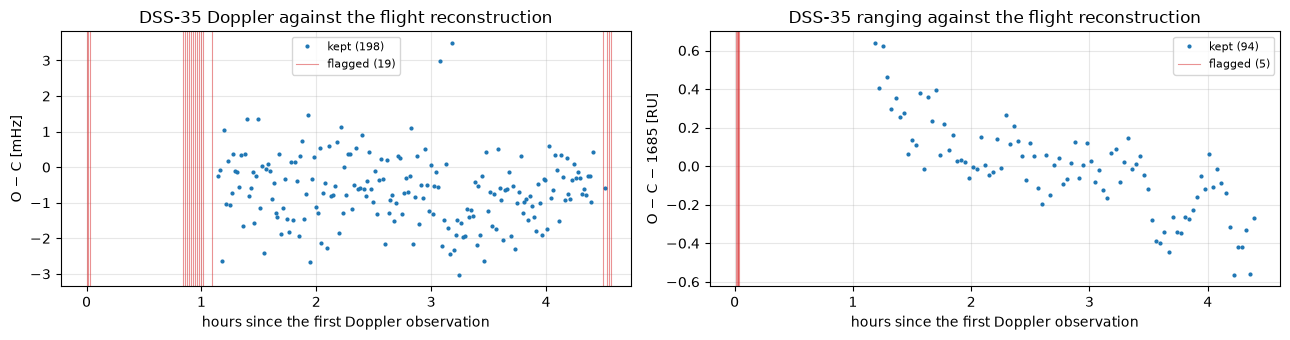

In [8]:
t_hours = {model.name: (observed[0] - t_doppler[0]).convert_to(hr).values
           for model, observed in [(doppler, observed_doppler), (ranging, observed_ranging)]}
offset = np.median(oc[ranging.name][~flags[ranging.name]])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, model, shift, scale, ylabel in [(ax[0], doppler, 0.0, 1e3, "O − C [mHz]"),
                                       (ax[1], ranging, offset, 1.0, f"O − C − {offset:.0f} [RU]")]:
    keep = ~flags[model.name]
    t = t_hours[model.name]
    a.plot(t[keep], (oc[model.name][keep] - shift) * scale, ".", ms=4, label=f"kept ({keep.sum()})")
    for k, t_flagged in enumerate(t[~keep]):
        a.axvline(t_flagged, color="C3", lw=0.8, alpha=0.5, label=f"flagged ({(~keep).sum()})" if k == 0 else None)
    a.set(xlabel="hours since the first Doppler observation", ylabel=ylabel, title=f"{model.name} against the flight reconstruction")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()

The editor flags 19 Doppler observations: the first 15 of the pass and four at its end. It flags no ranging beyond the five no-data points, because the offset is the same for every point and does not count as scatter. The kept Doppler residuals scatter by about 1 mHz, about 0.02 mm/s in range-rate, around a mean below 1 mHz, and the re-estimated σ of 0.95 mHz confirms the assumed 1 mHz. Around its offset, the ranging drifts by about 1 RU over the pass, with structure on a scale of an hour, but its point-to-point scatter is only 0.14 RU, about 2 cm of range, a third of the assumed 0.5 RU.

Agreement at this level validates the model chain (auxiliary data, ramp integration, light time, media corrections) for Doppler, and for ranging up to the offset:

<div style="border-left:4px solid #ea580c; background:rgba(234,88,12,0.12); padding:6px 10px; border-radius:4px">
🟠 <b>CHECK:</b> The first 15 Doppler points are off by −382 kHz, about −5,960 Hz and, for one, +3,681 Hz; possibly before the uplink ramp was stable. Scarabaeus flags round trips that start before the first ramp record, and none of these are flagged that way, so the cause is still open. The last four points drift by tens of mHz.
</div>

<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> Sequential ranging shows a nearly constant offset of about +1,685 RU (about 240 m of range) against the flight reconstruction, while Doppler agrees at the noise level. A constant offset points to a delay or calibration term rather than the trajectory; the transponder delay used for OSIRIS-REx (<code>trk234.SCFT_TRANSPD_DELAY_RU</code>) is the first suspect. Section 7 estimates it as a bias, which lets ranging into the fit but does not explain it.
</div>

The flags go back into the `meas_outliers` field of the observations ([chapter 3](03_tracking_data.ipynb)), which the filters respect:

In [9]:
observed_doppler = observed_doppler._replace(meas_outliers=flags[doppler.name].astype(float).tolist())
observed_ranging = observed_ranging._replace(meas_outliers=flags[ranging.name].astype(float).tolist())

## 6. Setting up the fit

The orbit determination setup is the one from [chapter 6](06_first_od_solution.ipynb), with these changes for a single pass of real data:

- **Propagation grid:** a 60-second grid from 04:30 to 11:30 UTC, passed to `reference_propagator()` as `tspan`. The real models evaluate the state at transmission and reflection times, not only at the observation time tags, and the arc is padded so that the light-time solution stays inside it.
- **A-priori state:** the flight reconstruction at the start of the arc plus a known error of 10 km and 1 cm/s per axis, with a 1σ of 30 km and 3 cm/s per axis.
- **Range bias:** a `range_bias_RU_DSS35` parameter owned by the station, estimated, with an a-priori of 0 ± 2,000 RU (about 280 m), wide enough to cover the offset. It is declared like $\eta_\text{SRP}$ in [chapter 8](08_estimating_more.ipynb).
- **Weights:** the σ's the editor re-estimated, passed by dataset name with `FilterSettings(measurement_sigmas=...)`.

Two fits, to see what ranging adds: Doppler alone, and Doppler with ranging and the bias.

In [10]:
pass_epochs = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-08T04:30:00"),
                                      scb.SpiceManager.utc2et("2018-06-08T11:30:00"),
                                      dt=scb.ArrayWUnits(60, sec), sys="TDB")

x_flight0 = orex_flight.get_state(pass_epochs[0], reference_frame="J2000", origin="SUN")
r_apriori = x_flight0.quantity[:3] + scb.ArrayWUnits([10.0] * 3, km)
v_apriori = x_flight0.quantity[3:] + scb.ArrayWUnits([0.01] * 3, m / sec).convert_to(km / sec)
state = scb.StateDefinition().position(reference, scb.ArrayWFrame(r_apriori, J2000)).velocity(reference, scb.ArrayWFrame(v_apriori, J2000))
state_bias = (scb.StateDefinition()
              .position(reference, scb.ArrayWFrame(r_apriori, J2000))
              .velocity(reference, scb.ArrayWFrame(v_apriori, J2000))
              .param("range_bias_RU_DSS35", station, scb.ArrayWFrame(scb.ArrayWUnits([0.0], None), J2000),
                     estimation="estimated", dynamics="static"))

sigma_apriori = [scb.ArrayWUnits(30.0, km)] * 3 + [scb.ArrayWUnits(0.03, m / sec).convert_to(km / sec)] * 3
P0 = scb.CovarianceMatrix(sigma_apriori, pass_epochs[0], from_list=True)
P0_bias = scb.CovarianceMatrix(sigma_apriori + [scb.ArrayWUnits(2000.0, None)], pass_epochs[0], from_list=True)

fits = {  # label: (state definition, a-priori covariance, measurements)
    "Doppler only": (state, P0, [(doppler, observed_doppler)]),
    "Doppler + ranging, bias estimated": (state_bias, P0_bias, [(doppler, observed_doppler), (ranging, observed_ranging)]),
}

## 7. The fits

The filter call is the one from [chapter 6](06_first_od_solution.ipynb). The comparison with the flight reconstruction is computed right after each fit, every 10 minutes over the pass, with `propagate_state_covariance`. Doppler and ranging measure along the line of sight from Earth, so the errors are split into that direction and the plane of the sky perpendicular to it:

In [11]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
t_pass = pass_epochs[::10]
# 🔵 TODO: get_state takes one epoch at a time; replace the loops once it accepts an EpochArray
x_flight = np.array([orex_flight.get_state(t, reference_frame="J2000", origin="SUN").quantity.values for t in t_pass])
r_earth = np.array([orex_flight.get_state(t, reference_frame="J2000", origin="EARTH").quantity.values[:3] for t in t_pass])
u = r_earth / np.linalg.norm(r_earth, axis=1, keepdims=True)  # line of sight from Earth

results = {}
for label, (state_definition, P0_fit, measurements) in fits.items():
    srifb = scb.SRIFB(propagator=reference_propagator(reference, state_definition, tspan=pass_epochs),
                      measurements=scb.MeasurementSpec.many(*[
                          scb.MeasurementSpec(model=model, observed_meas=observed, dataset_name=model.name)
                          for model, observed in measurements]),
                      settings=scb.FilterSettings(initial_covariance=P0_fit,
                                                  measurement_sigmas={model.name: refit_sigmas[model.name] for model, _ in measurements}),
                      traj_name="reference_real.bsp", traj_dir=str(out))
    solution, n_iterations, converged = srifb.fit(traj_name="reference_real.bsp", traj_dir=str(out))

    # 🔵 TODO: compare right after each fit; read later, results return the last fit's values (scb_suggestions.md 6.79)
    predicted = solution.propagate_state_covariance(t_pass)
    x_est = np.array([state_k.values0.values for state_k, _ in predicted])
    covariances = [P for _, P in predicted]
    dx = x_est[:, :6] - x_flight
    results[label] = {
        "iterations": n_iterations, "converged": converged,
        "postfit": {name: np.sqrt(np.mean([(r / s) ** 2 for r, s, *_ in residuals])) for name, residuals in solution.postfits.items()},
        "r_error": np.linalg.norm(dx[:, :3], axis=1),
        "r_sigma": np.array([np.trace(P[:3, :3]) ** 0.5 for P in covariances]),
        "r_los_error": np.sum(dx[:, :3] * u, axis=1),
        "r_los_sigma": np.array([(uk @ P[:3, :3] @ uk) ** 0.5 for uk, P in zip(u, covariances)]),
        "v_los_error": np.sum(dx[:, 3:] * u, axis=1),
        "v_los_sigma": np.array([(uk @ P[3:6, 3:6] @ uk) ** 0.5 for uk, P in zip(u, covariances)]),
        "dr": dx[:, :3], "P_r": [P[:3, :3] for P in covariances],
    }
    if x_est.shape[1] > 6:
        P = covariances[0]
        results[label]["bias"] = x_est[0, 6], P[6, 6] ** 0.5, (u[0] @ P[:3, 6]) / ((u[0] @ P[:3, :3] @ u[0]) * P[6, 6]) ** 0.5

solution.save(out / "solution.json")  # the fit with ranging

In [12]:
for label, r in results.items():
    print(f"{label}: converged {r['converged']} after {r['iterations']} iterations; post-fit RMS/σ "
          + ", ".join(f"{name} {value:.2f}" for name, value in r["postfit"].items()))
    print(f"    position error {r['r_error'][0]:.1f} km (1σ {r['r_sigma'][0]:.1f} km RSS); line of sight {r['r_los_error'][0]:+.2f} km "
          f"(1σ {r['r_los_sigma'][0]:.2f} km); LOS velocity {r['v_los_error'][0] * 1e6:+.2f} mm/s (1σ {r['v_los_sigma'][0] * 1e6:.2f} mm/s)")
    if "bias" in r:
        bias, sigma_bias, correlation = r["bias"]
        print(f"    range bias {bias:+.0f} ± {sigma_bias:.0f} RU; correlation with the line-of-sight position {correlation:+.6f}")

Doppler only: converged True after 2 iterations; post-fit RMS/σ DSS-35 Doppler 0.99
    position error 23.5 km (1σ 33.1 km RSS); line of sight -14.59 km (1σ 29.95 km); LOS velocity -0.70 mm/s (1σ 0.61 mm/s)
Doppler + ranging, bias estimated: converged True after 5 iterations; post-fit RMS/σ DSS-35 Doppler 1.03, DSS-35 ranging 1.00
    position error 13.3 km (1σ 13.3 km RSS); line of sight +0.24 km (1σ 0.28 km); LOS velocity -0.76 mm/s (1σ 0.61 mm/s)
    range bias +9 ± 2000 RU; correlation with the line-of-sight position -0.999996


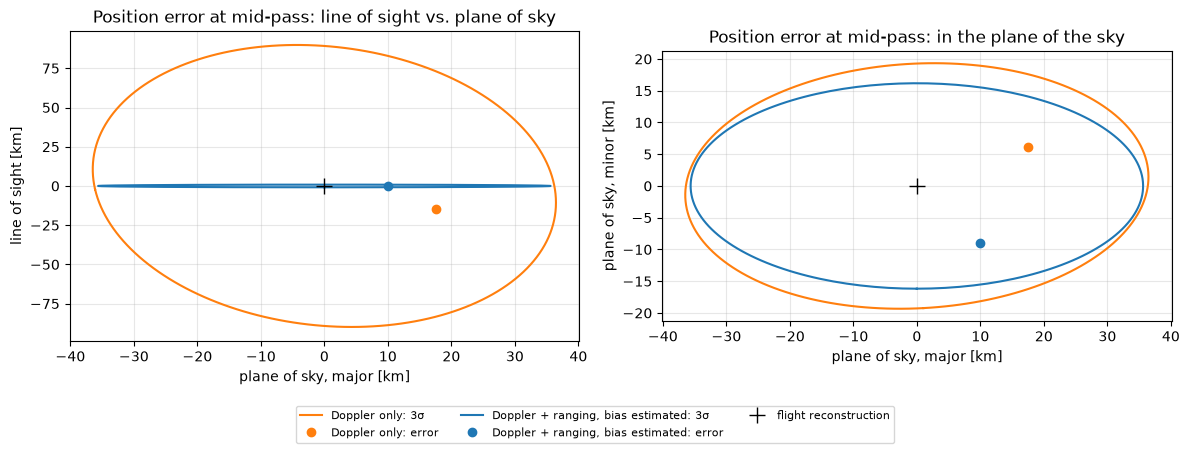

In [13]:
# Line of sight and the plane-of-sky axes of the ranging fit's position covariance, at mid-pass
k = len(t_pass) // 2
P_ranging = results["Doppler + ranging, bias estimated"]["P_r"][k]
projector = np.eye(3) - np.outer(u[k], u[k])
eigenvalues, eigenvectors = np.linalg.eigh(projector @ P_ranging @ projector)
axes = {"line of sight": u[k], "plane of sky, major": eigenvectors[:, 2], "plane of sky, minor": eigenvectors[:, 1]}
basis = np.array(list(axes.values()))
angle = np.linspace(0, 2 * np.pi, 200)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (i, j) in zip(ax, [(1, 0), (1, 2)]):
    for color, (label, r) in zip(["C1", "C0"], results.items()):
        error = basis @ r["dr"][k]
        cov = (basis @ r["P_r"][k] @ basis.T)[np.ix_([i, j], [i, j])]
        w, v = np.linalg.eigh(cov)
        ellipse = 3 * v @ np.diag(np.sqrt(w)) @ np.array([np.cos(angle), np.sin(angle)])
        a.plot(ellipse[0], ellipse[1], color=color, label=f"{label}: 3σ")
        a.plot(error[i], error[j], "o", color=color, label=f"{label}: error")
    a.plot(0, 0, "k+", ms=12, label="flight reconstruction")
    names = list(axes)
    a.set(xlabel=f"{names[i]} [km]", ylabel=f"{names[j]} [km]")
    a.grid(alpha=0.3)
ax[0].set_title("Position error at mid-pass: line of sight vs. plane of sky")
ax[1].set_title("Position error at mid-pass: in the plane of the sky")
ax[1].set_aspect("equal")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8)
plt.tight_layout(rect=(0, 0.1, 1, 1))

Both fits converge, and with the re-estimated weights the post-fit RMS is at 1σ for both data types.

**Doppler only.** The line-of-sight velocity, which Doppler measures directly, goes from the a-priori error of about 17 mm/s to 0.7 mm/s, within its 1σ of 0.6 mm/s. The line-of-sight position is barely constrained: −15 km, with a 3σ of about 90 km (the large orange ellipse).

**Adding ranging.** The line-of-sight position is now known to 0.28 km (1σ), a hundred times better, and the ellipse collapses to a thin sliver along the plane of the sky. The plane of the sky is measured by neither data type; it is constrained only through the dynamics and the Earth's rotation during the pass, and stays at about 13 km in both fits (right panel).

**The range bias is not determined.** It ends at +9 ± 2,000 RU, its a-priori, and its correlation with the line-of-sight position is −0.999996. Over a single pass, a constant range bias and the distance to the spacecraft change every ranging observation in the same way, so the data cannot separate them. The offset therefore went into the position: the 0.24 km line-of-sight error is the 1,685 RU offset (at about 0.14 m per RU). The a-priori σ of the bias sets how far the position may move to absorb it, which is why the 1σ is 0.28 km.

Separating a bias from the range needs geometry that changes: passes from other complexes, or on other days, when the trajectory ties the ranges together. Until then, the a-priori on the bias is a statement about the calibration, and a constant ranging offset limits the line-of-sight position to its size.

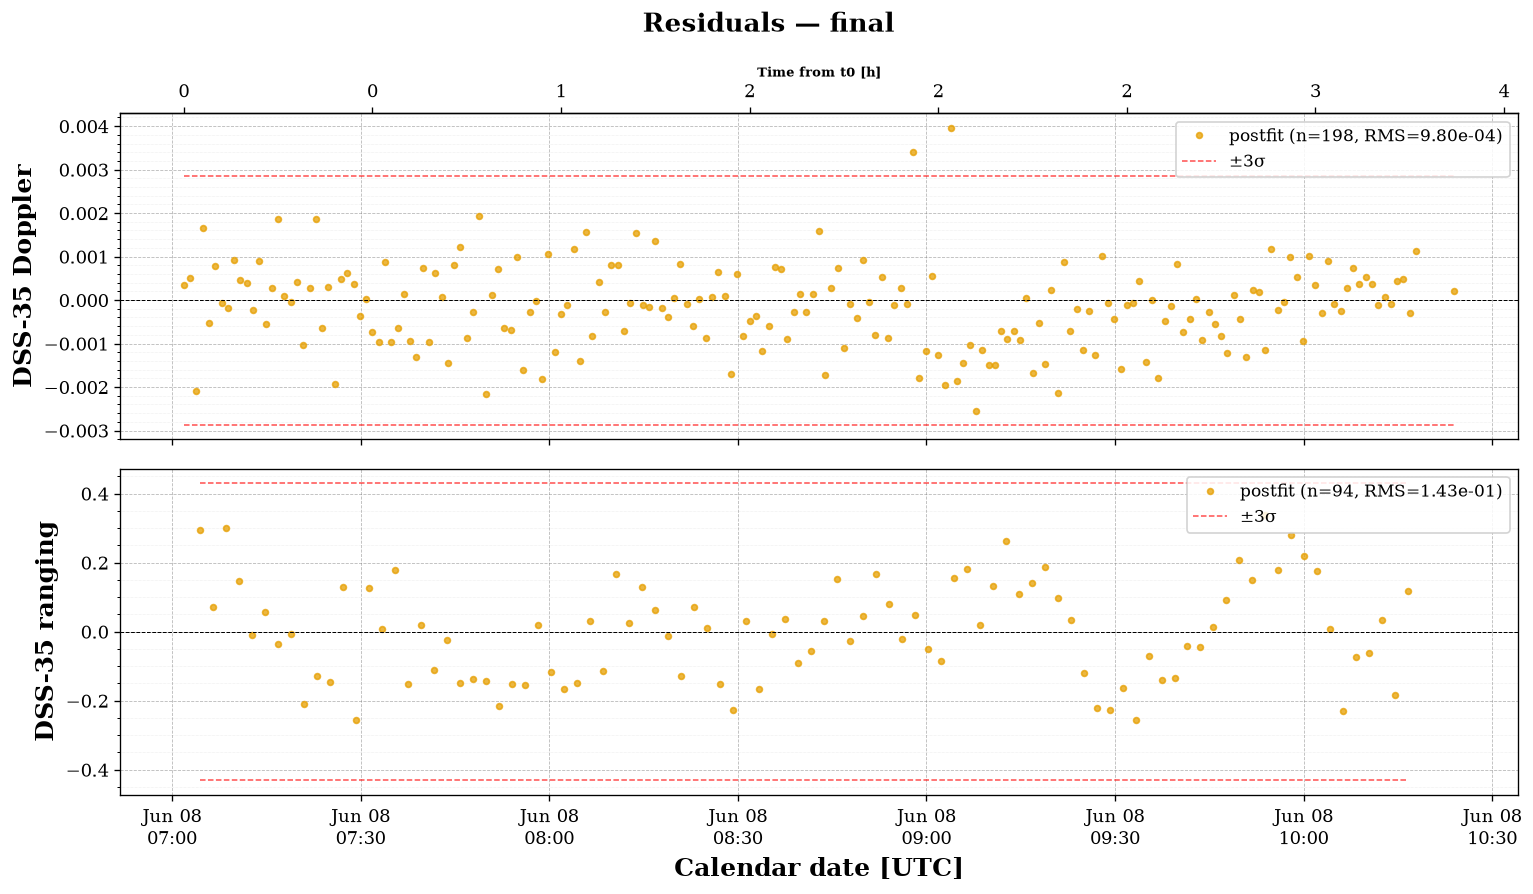

In [14]:
scb.Plotting.plot_residuals_json(out / "solution.json", iteration="final", kind="postfit", time_unit="hr");

The post-fit Doppler residuals are white and within ±3σ apart from two points near 09:00, the two that already stood out against the reconstruction (section 5) but stayed below the editor's 5σ threshold. The ranging residuals are within ±3σ but not white: they keep a slow variation of about ±0.2 RU, a few centimeters, on a scale of an hour. One candidate is the ionosphere, which section 3 left unmodeled for lack of a calibration file; at X-band it changes the range by centimeters over a pass.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Real Doppler and ranging | `DopplerReal`, `SequentialRangingReal` with `computed_measurements_dict` (auxiliary data) |
| Reading DSN observables | `observed_measurements(file, meas_name="2W_doppler" / "2W_sranging", units=...)` |
| Media corrections | `MediaCorrections(tropo_seasonal_file_path=...)`, `find_tro_metadata`, `find_ion_metadata` |
| Residuals against a reference trajectory | `model.generate_measurement_dataset(target=..., observed_meas=...)` |
| Editing raw data | `MeasurementEditing(datasets).huber_mad_filter(n_sigma=...)`, `outlier_flags`, `ObsData.meas_outliers` |
| Editing inside the fit | `FilterSettings(editing_method=..., editing_kwargs=...)` |
| Measurement weights | `FilterSettings(measurement_sigmas={dataset name: σ})` |
| Range bias | `StateDefinition.param("range_bias_RU_<tag>", station, value, estimation="estimated", dynamics="static")` |
| Propagator on another grid | `reference_propagator(spacecraft, state, tspan=...)` in `scenario.py` |
| Residuals of the fit | `SolutionOD.save(path)`, `Plotting.plot_residuals_json(path, iteration=..., kind=...)` |

The pipeline from chapters [4](04_filter_dynamics.ipynb)–[6](06_first_od_solution.ipynb) is unchanged with real data; what changes is the measurement model and the care the data need: validation against an independent trajectory, editing, realistic weights, and parameters for the calibrations that are not known.

→ *How-tos: Media corrections & ramp tables* for the details of the delay models.